# Evaluate EfficientNetV2-S — Brain MRI Classification

**This notebook does not train the model.** It loads a saved checkpoint from the training notebook and evaluates it on the saved test split.

Prerequisites:
- Run data preparation so `prepared_data/test.csv` exists.
- Run `02_Train_EfficientNetV2-S.ipynb` at least once so `trained_models/efficientnet_v2_s_best.pth` exists.
- Keep the CSV paths and image files in their expected locations.

## 1. Imports and paths

In [9]:
# %pip install pandas pillow matplotlib scikit-learn torch torchvision

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import efficientnet_v2_s, EfficientNet_V2_S_Weights

from sklearn.metrics import (
    accuracy_score, f1_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)

DATA_DIR = Path("prepared_data")
TEST_CSV = DATA_DIR / "test.csv"
CHECKPOINT_PATH = Path("trained_models") / "efficientnet_v2_s_best.pth"

BATCH_SIZE = 16 if torch.cuda.is_available() else 8
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


## 2. Load the saved test split and checkpoint

In [10]:
if not TEST_CSV.exists():
    raise FileNotFoundError(
        f"Missing {TEST_CSV}. Run the data-preparation notebook first."
    )
if not CHECKPOINT_PATH.exists():
    raise FileNotFoundError(
        f"Missing {CHECKPOINT_PATH}. Run the training notebook first."
    )

test_df = pd.read_csv(TEST_CSV)

# weights_only=False is needed for checkpoints containing metadata on some
# PyTorch versions. Only load checkpoints you created yourself.
try:
    checkpoint = torch.load(
        CHECKPOINT_PATH, map_location=device, weights_only=False
    )
except TypeError:  # compatibility with older PyTorch versions
    checkpoint = torch.load(CHECKPOINT_PATH, map_location=device)

class_names = checkpoint["class_names"]
class_to_idx = checkpoint["class_to_idx"]
idx_to_class = {i: name for name, i in class_to_idx.items()}

print("Checkpoint architecture:", checkpoint["architecture"])
print("Classes:", class_to_idx)
print("Test images:", len(test_df))

Checkpoint architecture: efficientnet_v2_s
Classes: {'glioma_tumor': 0, 'meningioma_tumor': 1, 'normal': 2, 'pituitary_tumor': 3}
Test images: 427


## 3. Build the test dataloader

In [11]:
weights = EfficientNet_V2_S_Weights.DEFAULT
eval_transform = weights.transforms()

class BrainMRIDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True).copy()
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]
        with Image.open(row["filepath"]) as img:
            image = img.convert("RGB")
        label = class_to_idx[row["class"]]
        if self.transform:
            image = self.transform(image)
        return image, label

test_dataset = BrainMRIDataset(test_df, eval_transform)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0
)

## 4. Load the trained model

In [12]:
model = efficientnet_v2_s(weights=None)
model.classifier[1] = nn.Linear(
    model.classifier[1].in_features, len(class_names)
)
model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(device)
model.eval()

print("Loaded saved model weights. No training will be performed.")

Loaded saved model weights. No training will be performed.


## 5. Evaluate on the test set

In [13]:
all_labels = []
all_confidences = []
all_predictions = []

model.eval()
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        probabilities = torch.softmax(outputs, dim=1)
        predictions = probabilities.argmax(dim=1).cpu().numpy()
        all_confidences.extend(probabilities.max(dim=1).values.cpu().tolist())

        all_predictions.extend(predictions.tolist())
        all_labels.extend(labels.numpy().tolist())

accuracy = accuracy_score(all_labels, all_predictions)
macro_f1 = f1_score(all_labels, all_predictions, average="macro")

print(f"Test accuracy: {accuracy:.4f}")
print(f"Test macro F1-score: {macro_f1:.4f}")
print("\nClassification report:")
print(classification_report(
    all_labels,
    all_predictions,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0,
    digits=4
))

Test accuracy: 0.9485
Test macro F1-score: 0.9531

Classification report:
                  precision    recall  f1-score   support

    glioma_tumor     0.9021    0.9699    0.9348       133
meningioma_tumor     0.9908    0.8780    0.9310       123
          normal     1.0000    0.9565    0.9778        46
 pituitary_tumor     0.9466    0.9920    0.9688       125

        accuracy                         0.9485       427
       macro avg     0.9599    0.9491    0.9531       427
    weighted avg     0.9512    0.9485    0.9483       427



## 6. Confusion matrix

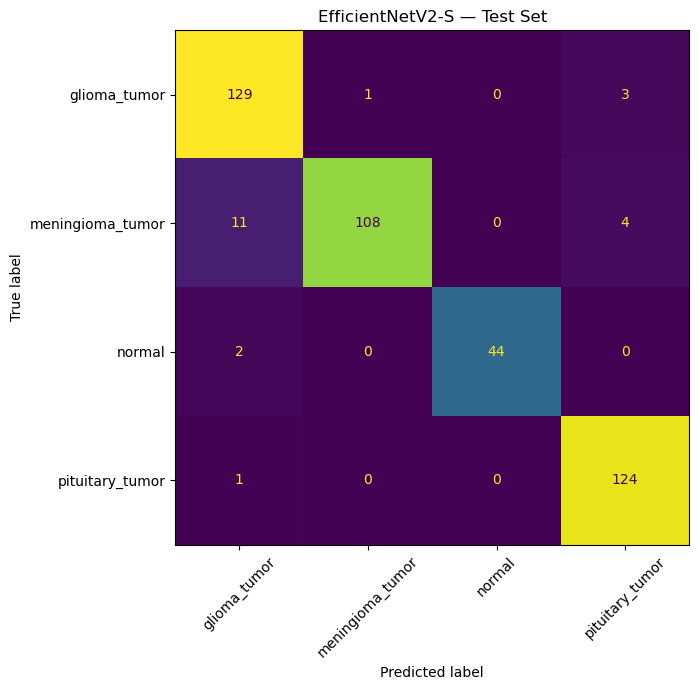

In [14]:
cm = confusion_matrix(
    all_labels, all_predictions, labels=list(range(len(class_names)))
)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm, display_labels=class_names
)
fig, ax = plt.subplots(figsize=(8, 7))
disp.plot(ax=ax, xticks_rotation=45, values_format="d", colorbar=False)
ax.set_title("EfficientNetV2-S — Test Set")
plt.tight_layout()
plt.show()

## 7. Optional: save predictions for later analysis

## 8. Inspect misclassified images

This lists every test image whose predicted class differs from its true class and displays the images for visual inspection.


Misclassified images: 22 of 427


,filepath,true_label,predicted_label,confidence
339,C:\Users\rickv\School\Jaar3\minor\Challenge\Br...,meningioma_tumor,pituitary_tumor,0.992966
210,C:\Users\rickv\School\Jaar3\minor\Challenge\Br...,meningioma_tumor,glioma_tumor,0.986876
18,C:\Users\rickv\School\Jaar3\minor\Challenge\Br...,meningioma_tumor,glioma_tumor,0.966810
329,C:\Users\rickv\School\Jaar3\minor\Challenge\Br...,meningioma_tumor,glioma_tumor,0.964852
244,C:\Users\rickv\School\Jaar3\minor\Challenge\Br...,meningioma_tumor,pituitary_tumor,0.943599
82,C:\Users\rickv\School\Jaar3\minor\Challenge\Br...,glioma_tumor,pituitary_tumor,0.941861
144,C:\Users\rickv\School\Jaar3\minor\Challenge\Br...,meningioma_tumor,glioma_tumor,0.940141
171,C:\Users\rickv\School\Jaar3\minor\Challenge\Br...,meningioma_tumor,pituitary_tumor,0.927536
344,C:\Users\rickv\School\Jaar3\minor\Challenge\Br...,meningioma_tumor,glioma_tumor,0.852103
326,C:\Users\rickv\School\Jaar3\minor\Challenge\Br...,glioma_tumor,meningioma_tumor,0.833295


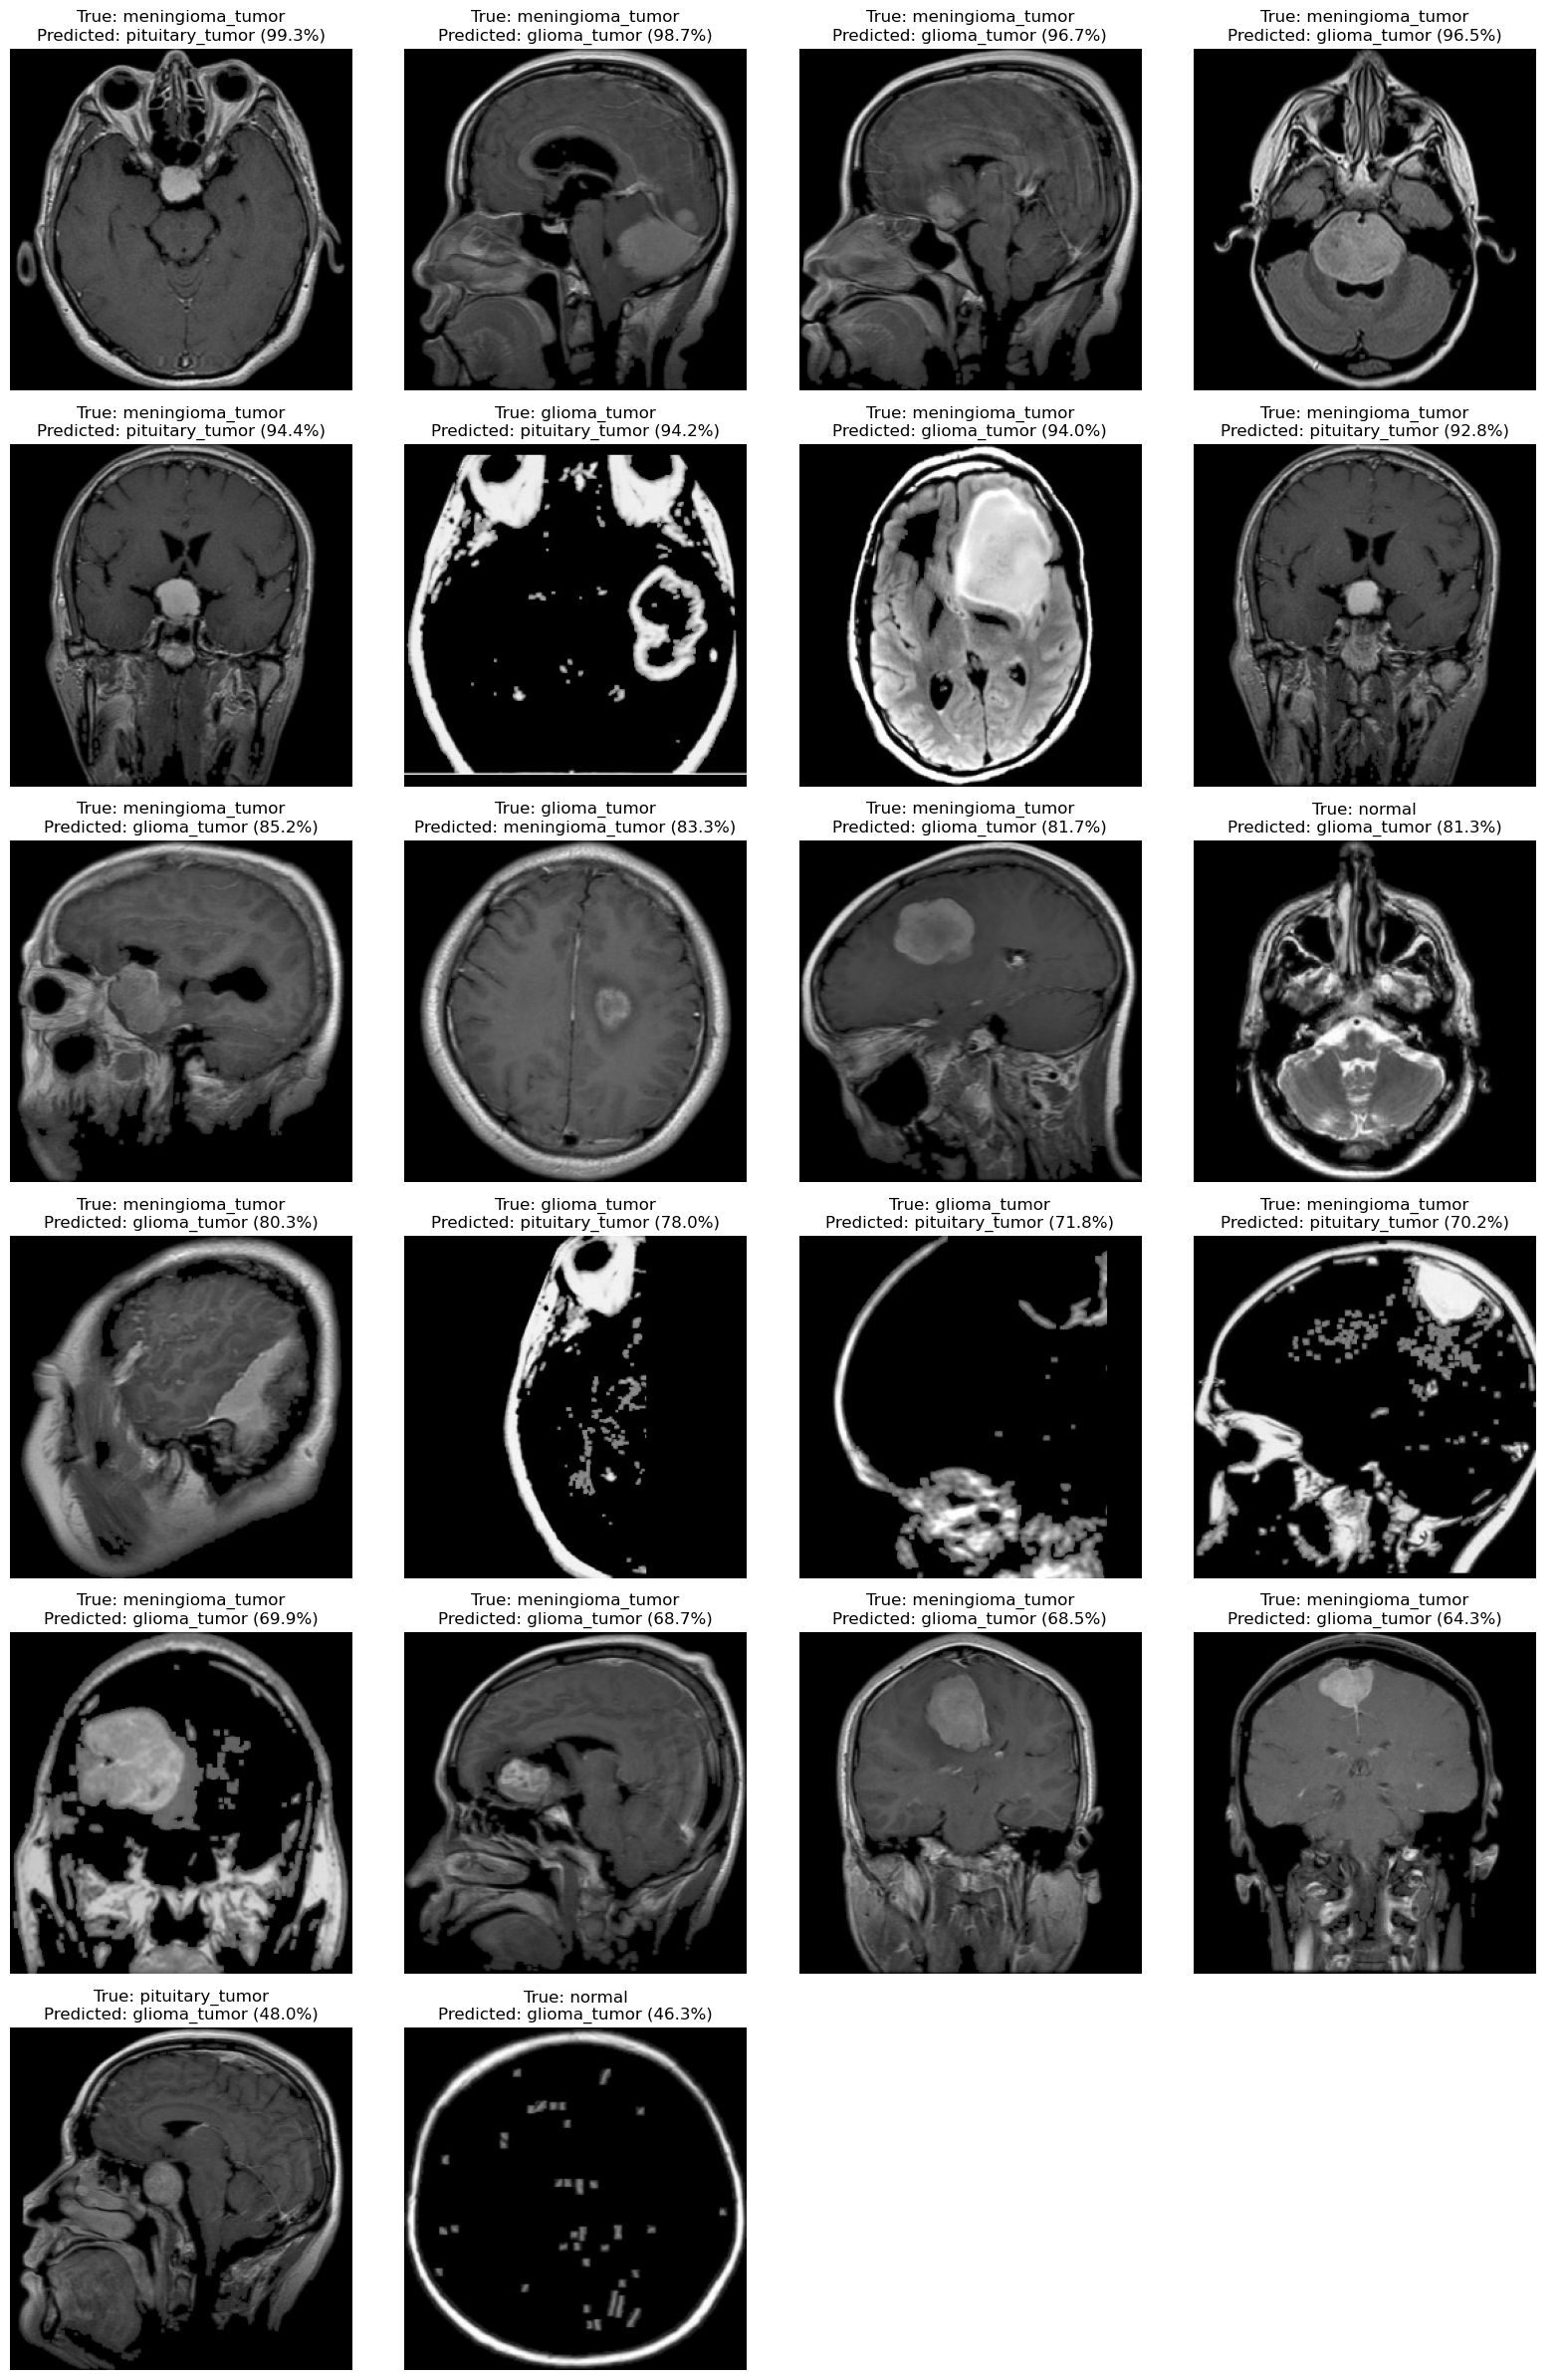

In [15]:
results_df=test_df.copy()
results_df["true_label"]=[idx_to_class[i] for i in all_labels]
results_df["predicted_label"]=[idx_to_class[i] for i in all_predictions]
results_df["confidence"]=all_confidences
misclassified_df=results_df[results_df["true_label"]!=results_df["predicted_label"]].copy()
misclassified_df=misclassified_df.sort_values("confidence",ascending=False)
print(f"Misclassified images: {len(misclassified_df)} of {len(results_df)}")
display(misclassified_df[["filepath","true_label","predicted_label","confidence"]])
misclassified_df.to_csv(Path("trained_models")/"efficientnet_v2_s_misclassified_images.csv",index=False)
columns=4
rows=(len(misclassified_df)+columns-1)//columns
if rows:
    fig,axes=plt.subplots(rows,columns,figsize=(16,4*rows))
    axes=np.atleast_1d(axes).ravel()
    for ax,(_,row) in zip(axes,misclassified_df.iterrows()):
        image=Image.open(row["filepath"])
        ax.imshow(image,cmap="gray")
        ax.set_title(f"True: {row['true_label']}\nPredicted: {row['predicted_label']} ({row['confidence']:.1%})")
        ax.axis("off")
    for ax in axes[len(misclassified_df):]: ax.axis("off")
    plt.tight_layout()
    plt.show()


In [16]:
results_df = test_df.copy()
results_df["true_label"] = [idx_to_class[i] for i in all_labels]
results_df["predicted_label"] = [idx_to_class[i] for i in all_predictions]
results_df["correct"] = results_df["true_label"] == results_df["predicted_label"]

prediction_path = Path("trained_models") / "efficientnet_v2_s_test_predictions.csv"
prediction_path.parent.mkdir(parents=True, exist_ok=True)
results_df.to_csv(prediction_path, index=False)

print("Saved test predictions to:", prediction_path.resolve())

Saved test predictions to: C:\Users\rickv\School\Jaar3\minor\Challenge\Brain-Tumor\brain_tumors\trained_models\efficientnet_v2_s_test_predictions.csv
